# Case 1: order funnel and cohort retention on Olist

This notebook reads the numbers that `analysis.py` wrote to `results/case1.json`, runs two of the
named queries live so the SQL can be inspected, and shows the figures. The memo is `memo.md`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from product_analytics_cases.common import CASES, RESULTS, connect, run_sql

HERE = CASES / "01_funnel_retention"
res = json.loads((RESULTS / "case1.json").read_text(encoding="utf-8"))
numbers = pd.DataFrame([{"key": k, **v} for k, v in res["numbers"].items()]).set_index("key")
numbers

,value,source,unit
key,,,
rows_read,401992,sql/rows_read.sql,
window_approved_pct,99.877891,sql/funnel_by_month.sql + window_totals(),%
window_handed_to_carrier_pct,98.389427,sql/funnel_by_month.sql + window_totals(),%
window_delivered_pct,98.795403,sql/funnel_by_month.sql + window_totals(),%
window_reviewed_pct,99.331629,sql/funnel_by_month.sql + window_totals(),%
window_cancel_pct,1.192831,sql/funnel_by_month.sql + window_totals(),%
window_orders,99092,sql/funnel_by_month.sql + window_totals(),
window_worst_step,handed_to_carrier,sql/funnel_by_month.sql + window_totals(),
window_worst_step_loss_pct,1.610573,sql/funnel_by_month.sql + window_totals(),%


## The funnel query, run live

In [2]:
con = connect("olist")
funnel = run_sql(con, HERE, "funnel_by_month.sql")
funnel.tail(8)

,month,created,approved,handed_to_carrier,delivered,reviewed,canceled,unavailable
17,2018-03,7211,7208.0,7138.0,7003.0,6948.0,26.0,17.0
18,2018-04,6939,6939.0,6897.0,6798.0,6752.0,15.0,5.0
19,2018-05,6873,6872.0,6803.0,6749.0,6722.0,24.0,16.0
20,2018-06,6167,6167.0,6142.0,6096.0,6072.0,18.0,4.0
21,2018-07,6292,6291.0,6219.0,6156.0,6118.0,41.0,18.0
22,2018-08,6512,6459.0,6398.0,6351.0,6330.0,84.0,7.0
23,2018-09,16,1.0,1.0,0.0,0.0,15.0,0.0
24,2018-10,4,0.0,0.0,0.0,0.0,4.0,0.0


In [3]:
print(Path(HERE / "sql" / "funnel_by_month.sql").read_text(encoding="utf-8"))

-- Order funnel by purchase month: created, approved, handed to carrier, delivered, reviewed.
-- Steps are cumulative. An order that reached a later step counts as having passed the earlier
-- ones, so the funnel stays monotone where an earlier timestamp is missing (14 delivered orders
-- have no approval stamp). "Reviewed" means a delivered order with at least one review row.
WITH o AS (
    SELECT
        order_id,
        strftime(order_purchase_timestamp, '%Y-%m') AS month,
        order_status,
        (order_approved_at IS NOT NULL OR order_delivered_carrier_date IS NOT NULL
            OR order_delivered_customer_date IS NOT NULL) AS approved,
        (order_delivered_carrier_date IS NOT NULL OR order_delivered_customer_date IS NOT NULL) AS carrier,
        (order_delivered_customer_date IS NOT NULL) AS delivered
    FROM orders
), r AS (
    SELECT DISTINCT order_id FROM reviews
)
SELECT
    month,
    COUNT(*) AS created,
    SUM(approved::INT) AS approved,
    SUM(carrier::IN

## Cohort matrix (twelve cohorts by six months, cumulative share with a second order, %)

In [4]:
t = res["tables"]["cohort_matrix_12x6"]
pd.DataFrame(t["rows"], columns=t["columns"]).round(2)

,cohort,customers,month_1_pct,month_2_pct,month_3_pct,month_4_pct,month_5_pct,month_6_pct
0,2017-03,2636,1.59,1.82,2.31,2.62,2.73,2.77
1,2017-04,2352,1.28,1.62,1.87,1.91,2.25,2.59
2,2017-05,3596,1.84,2.25,2.59,2.86,3.17,3.39
3,2017-06,3139,1.78,2.20,2.68,2.96,3.09,3.54
4,2017-07,3894,1.72,2.08,2.26,2.49,2.77,2.98
5,2017-08,4184,1.67,2.25,2.44,2.77,3.06,3.37
6,2017-09,4130,1.67,2.11,2.54,2.81,3.12,3.27
7,2017-10,4470,1.45,2.01,2.08,2.19,2.39,2.53
8,2017-11,7304,1.48,1.81,2.05,2.22,2.36,2.55
9,2017-12,5487,0.93,1.22,1.57,1.77,2.06,2.22


## Lateness and review score

In [5]:
t = res["tables"]["lateness_buckets"]
pd.DataFrame(t["rows"], columns=t["columns"]).round(2)

,bucket,bucket_min,orders,mean_score,one_star_pct
0,on time or early,-147,89443,4.29,6.62
1,1 to 7 days late,1,3600,2.71,41.36
2,8 to 14 days late,8,1446,1.67,70.61
3,more than 14 days late,15,1335,1.72,68.99


funnel_conversion_by_month from sql/funnel_by_month.sql + plot_funnel()


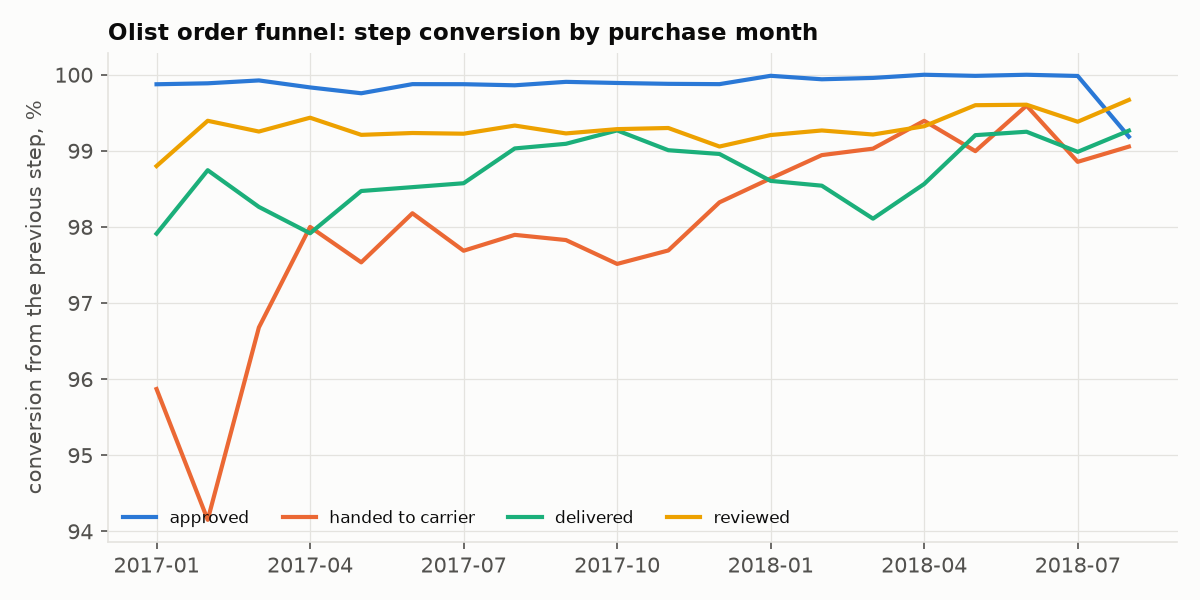

cohort_retention_matrix from sql/cohort_retention.sql + plot_cohorts()


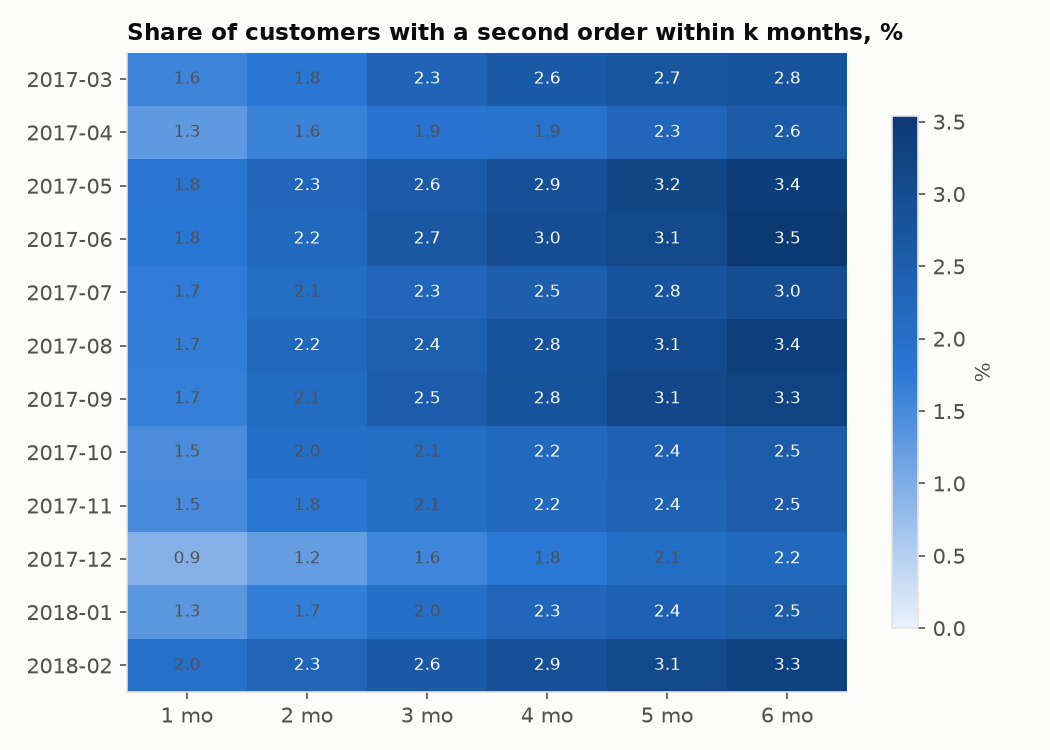

lateness_vs_review from sql/lateness_review.sql + plot_lateness()


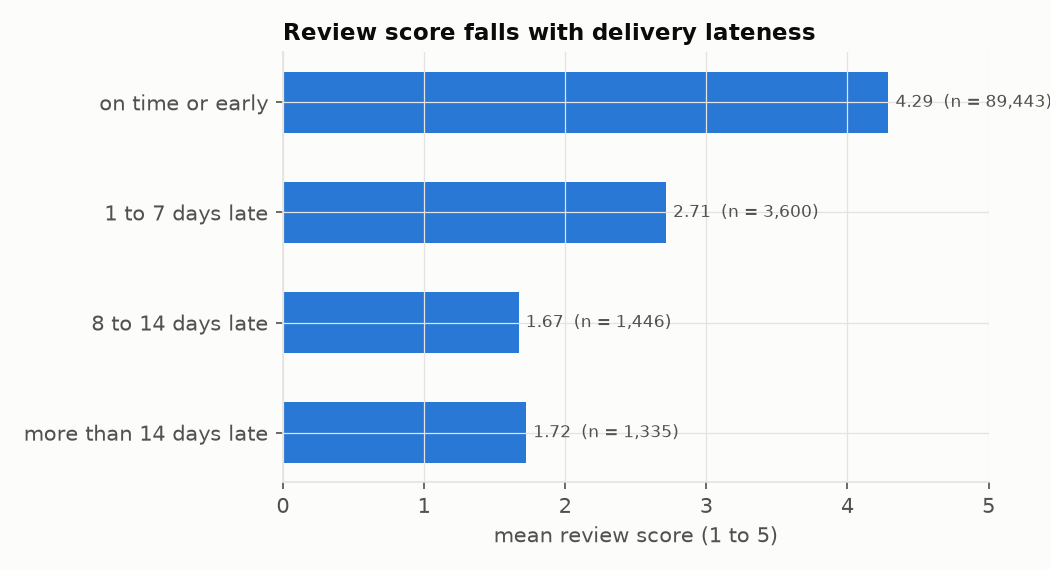

In [6]:
for key, fig in res["figures"].items():
    print(key, "from", fig["source"])
    display(Image(filename=str(RESULTS.parent / fig["file"])))